# Deep Retention — Construcción y entrenamiento de la red neuronal

Este notebook utiliza los artefactos generados por `02_preprocesamiento.ipynb` para construir, entrenar y evaluar un perceptrón multicapa (MLP) encargado de estimar la probabilidad de abandono de clientes bancarios.

El entrenamiento se realiza exclusivamente con `train.npz`, utilizando `validation.npz` para monitorear el aprendizaje, seleccionar los mejores pesos y analizar las probabilidades estimadas.

Posteriormente, se aplica una corrección aproximada basada en los pesos de clase para mejorar la calibración de las probabilidades. Finalmente, el modelo y su configuración se exportan y se realiza una evaluación independiente utilizando `test.npz`.

El notebook no repite la limpieza, división ni transformación de los datos. El conjunto de prueba no participa en el entrenamiento, la selección del modelo ni la elección de la corrección.

## 1. Entorno y reproducibilidad

Se fijan semillas para NumPy y TensorFlow. La arquitectura y los hiperparámetros se mantienen sin cambios respecto al experimento anterior.

In [1]:
import json
import os
from pathlib import Path

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import tensorflow as tf
from IPython.display import display
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score
from sklearn.utils.class_weight import compute_class_weight

RANDOM_STATE = 42
SCHEMA_VERSION = "1.0"
MAX_EPOCHS = 100
BATCH_SIZE = 32

np.random.seed(RANDOM_STATE)
tf.keras.utils.set_random_seed(RANDOM_STATE)
try:
    tf.config.experimental.enable_op_determinism()
except Exception as error:
    print(f"Determinismo estricto no disponible: {error}")

print(f"TensorFlow: {tf.__version__}")
print(f"Keras: {tf.keras.__version__}")
print(f"Scikit-learn: {sklearn.__version__}")
print("Dispositivos:", [device.device_type for device in tf.config.list_physical_devices()])

TensorFlow: 2.21.0
Keras: 3.15.1
Scikit-learn: 1.9.1
Dispositivos: ['CPU']


## 2. Carga de datos procesados

El procedimiento reproducible requiere ejecutar primero `02_preprocesamiento.ipynb`, encargado de generar las particiones, ajustar el preprocesador y exportar los artefactos correspondientes.

Este notebook utiliza inicialmente `train.npz` y `validation.npz` para entrenar y evaluar el MLP durante su desarrollo.

El conjunto `test.npz` permanece reservado hasta la evaluación final, realizada después de seleccionar la arquitectura, los mejores pesos y la corrección de probabilidades.

Se comprueba la compatibilidad de los archivos mediante sus dimensiones, tipos de datos, características y metadatos. Si alguna verificación falla, la ejecución se detiene.

In [ ]:
PROCESSED_CANDIDATES = [
    Path("data") / "processed",
    Path("..") / "data" / "processed",
]
PROCESSED_DIR = next((path for path in PROCESSED_CANDIDATES if path.is_dir()), None)
if PROCESSED_DIR is None:
    raise FileNotFoundError(
        "No existe data/processed. Ejecute primero notebooks/02_preprocesamiento.ipynb."
    )

TRAIN_PATH = PROCESSED_DIR / "train.npz"
VALIDATION_PATH = PROCESSED_DIR / "validation.npz"
METADATA_PATH = PROCESSED_DIR / "metadata.json"
required_paths = [TRAIN_PATH, VALIDATION_PATH, METADATA_PATH]
missing_paths = [path.as_posix() for path in required_paths if not path.is_file()]
if missing_paths:
    raise FileNotFoundError(
        "Faltan artefactos de preprocesamiento. Ejecute primero "
        f"notebooks/02_preprocesamiento.ipynb. Ausentes: {missing_paths}"
    )

metadata = json.loads(METADATA_PATH.read_text(encoding="utf-8"))

with np.load(TRAIN_PATH, allow_pickle=False) as train_artifact:
    X_train_processed = train_artifact["X"].copy()
    y_train_array = train_artifact["y"].copy()
    train_indices = train_artifact["indices"].copy()
    train_artifact_id = train_artifact["artifact_id"].item()

with np.load(VALIDATION_PATH, allow_pickle=False) as validation_artifact:
    X_val_processed = validation_artifact["X"].copy()
    y_val_array = validation_artifact["y"].copy()
    validation_indices = validation_artifact["indices"].copy()
    validation_artifact_id = validation_artifact["artifact_id"].item()

EXPECTED_TRANSFORMED_FEATURES = [
    "CreditScore", "Age", "Tenure", "Balance", "NumOfProducts", "EstimatedSalary",
    "Geography_France", "Geography_Germany", "Geography_Spain",
    "HasCrCard", "IsActiveMember",
]

compatibility_checks = {
    "Versión de esquema compatible": metadata.get("preprocessing_schema_version") == SCHEMA_VERSION,
    "Semilla compatible": metadata.get("split", {}).get("random_state") == RANDOM_STATE,
    "Nueve predictoras registradas": len(metadata.get("features", [])) == 9,
    "Orden de 11 características compatible": metadata.get("transformed_features") == EXPECTED_TRANSFORMED_FEATURES,
    "Dimensión de entrenamiento compatible": X_train_processed.shape == (7000, 11),
    "Dimensión de validación compatible": X_val_processed.shape == (1500, 11),
    "Etiquetas compatibles": y_train_array.shape == (7000,) and y_val_array.shape == (1500,),
    "Matrices float32": X_train_processed.dtype == X_val_processed.dtype == np.float32,
    "Etiquetas float32": y_train_array.dtype == y_val_array.dtype == np.float32,
    "Valores finitos": bool(np.isfinite(X_train_processed).all() and np.isfinite(X_val_processed).all()),
    "Etiquetas binarias": set(np.unique(y_train_array)) <= {0.0, 1.0} and set(np.unique(y_val_array)) <= {0.0, 1.0},
    "Índices sin solapamiento": not set(train_indices) & set(validation_indices),
    "Identificador común": train_artifact_id == validation_artifact_id == metadata.get("artifact_id"),
    "Versión de Scikit-learn compatible": metadata.get("scikit_learn_version") == sklearn.__version__,
}

failed_checks = [name for name, result in compatibility_checks.items() if not result]
if failed_checks:
    raise ValueError(
        "Los artefactos no son compatibles con este entrenamiento. "
        "Ejecute primero notebooks/02_preprocesamiento.ipynb. "
        f"Comprobaciones fallidas: {failed_checks}"
    )

display(pd.DataFrame({
    "comprobación": compatibility_checks.keys(),
    "resultado": compatibility_checks.values(),
}))
print("Directorio procesado:", PROCESSED_DIR.as_posix())
print("Identificador de artefactos:", metadata["artifact_id"])
print("Características:", metadata["transformed_features"])
print(
    "El conjunto test.npz se utilizará exclusivamente "
    "en la sección de evaluación final."
)

,comprobación,resultado
0,Versión de esquema compatible,True
1,Semilla compatible,True
2,Nueve predictoras registradas,True
3,Orden de 11 características compatible,True
4,Dimensión de entrenamiento compatible,True
5,Dimensión de validación compatible,True
6,Etiquetas compatibles,True
7,Matrices float32,True
8,Etiquetas float32,True
9,Valores finitos,True


Directorio procesado: ../data/processed
Identificador de artefactos: 3a2890fbab71e9c8
Características: ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'EstimatedSalary', 'Geography_France', 'Geography_Germany', 'Geography_Spain', 'HasCrCard', 'IsActiveMember']
El archivo test.npz no se carga en este notebook.


## 3. Ponderación de clases

Los pesos se calculan exclusivamente con `y_train_array` mediante `compute_class_weight(class_weight="balanced")`. La clase minoritaria contribuye más a la pérdida durante el ajuste; no se aplica SMOTE ni se duplican o eliminan clientes.

In [3]:
classes = np.array([0, 1], dtype=int)
training_labels = y_train_array.astype(int)
balanced_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=training_labels,
)
class_weights = {
    int(class_label): float(weight)
    for class_label, weight in zip(classes, balanced_weights)
}

class_counts = pd.Series(training_labels).value_counts().sort_index()
class_weight_summary = pd.DataFrame({
    "clase": classes,
    "significado": ["Permaneció", "Abandonó"],
    "clientes_entrenamiento": [int(class_counts.loc[class_label]) for class_label in classes],
    "porcentaje_entrenamiento": [
        class_counts.loc[class_label] / len(training_labels) * 100
        for class_label in classes
    ],
    "peso": [class_weights[int(class_label)] for class_label in classes],
})
display(class_weight_summary)
print("Diccionario para Keras:", class_weights)

,clase,significado,clientes_entrenamiento,porcentaje_entrenamiento,peso
0,0,Permaneció,5574,79.628571,0.627915
1,1,Abandonó,1426,20.371429,2.454418


Diccionario para Keras: {0: 0.6279153211338356, 1: 2.4544179523141656}


## 4. Arquitectura del MLP

La dimensión de entrada se obtiene dinámicamente de `X_train_processed`. Se conserva exactamente la arquitectura del experimento anterior.

In [4]:
input_dimension = X_train_processed.shape[1]

model = tf.keras.Sequential(
    [
        tf.keras.layers.Input(shape=(input_dimension,), name="input"),
        tf.keras.layers.Dense(128, activation="relu", name="dense_128"),
        tf.keras.layers.BatchNormalization(name="batch_normalization"),
        tf.keras.layers.Dropout(0.25, name="dropout_025"),
        tf.keras.layers.Dense(64, activation="relu", name="dense_64"),
        tf.keras.layers.Dropout(0.15, name="dropout_015"),
        tf.keras.layers.Dense(1, activation="sigmoid", name="output"),
    ],
    name="deep_retention_mlp",
)

model.summary()
print(f"Dimensión de entrada: {input_dimension}")
print(f"Parámetros totales: {model.count_params():,}")

Model: "deep_retention_mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_128 (Dense)               │ (None, 128)            │         1,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_025 (Dropout)           │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_64 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_015 (Dropout)           │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,369 (40.50 KB)

 Trainable params: 10,113 (39.50 KB)

 Non-trainable params: 256 (1.00 KB)

Dimensión de entrada: 11
Parámetros totales: 10,369


**Decisiones de arquitectura.** ReLU aporta no linealidad; `BatchNormalization` estabiliza activaciones; Dropout limita el sobreajuste; y Sigmoid produce una salida entre 0 y 1. Esa salida requiere evaluación de calibración posterior antes de utilizarse en decisiones financieras.

## 5. Compilación y Early Stopping

Se mantienen Adam, Binary Crossentropy, Binary Accuracy, ROC-AUC y PR-AUC. Early Stopping observa `val_loss`, utiliza paciencia 12 y restaura los mejores pesos.

In [5]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(),
    loss=tf.keras.losses.BinaryCrossentropy(),
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        tf.keras.metrics.AUC(name="roc_auc", curve="ROC"),
        tf.keras.metrics.AUC(name="pr_auc", curve="PR"),
    ],
)

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=12,
    restore_best_weights=True,
)

print("Optimizador: Adam")
print("Pérdida: BinaryCrossentropy")
print("Monitor:", early_stopping.monitor)
print("Paciencia:", early_stopping.patience)
print("Restaurar mejores pesos:", early_stopping.restore_best_weights)

Optimizador: Adam
Pérdida: BinaryCrossentropy
Monitor: val_loss
Paciencia: 12
Restaurar mejores pesos: True


## 6. Entrenamiento

El modelo recibe únicamente entrenamiento y validación. `class_weight` se aplica solo al entrenamiento; validación conserva su distribución original. `test.npz` permanece fuera del proceso.

In [6]:
history = model.fit(
    X_train_processed,
    y_train_array,
    validation_data=(X_val_processed, y_val_array),
    epochs=MAX_EPOCHS,
    batch_size=BATCH_SIZE,
    class_weight=class_weights,
    callbacks=[early_stopping],
    verbose=2,
)

history_df = pd.DataFrame(history.history)
epochs_executed = len(history_df)
best_epoch = int(history_df["val_loss"].idxmin() + 1)
best_val_loss = float(history_df["val_loss"].min())
early_stopping_applied = epochs_executed < MAX_EPOCHS

training_run_summary = pd.DataFrame({
    "configuración": [
        "Épocas máximas", "Épocas ejecutadas", "Mejor época por val_loss",
        "Mejor val_loss", "Batch size", "Early Stopping detuvo antes del máximo",
    ],
    "valor": [
        MAX_EPOCHS, epochs_executed, best_epoch,
        best_val_loss, BATCH_SIZE, early_stopping_applied,
    ],
})
display(training_run_summary)

Epoch 1/100
219/219 - 3s - 12ms/step - accuracy: 0.6806 - loss: 0.6170 - pr_auc: 0.4485 - roc_auc: 0.7401 - val_accuracy: 0.7467 - val_loss: 0.5501 - val_pr_auc: 0.6299 - val_roc_auc: 0.8414
Epoch 2/100
219/219 - 1s - 3ms/step - accuracy: 0.7297 - loss: 0.5452 - pr_auc: 0.5645 - roc_auc: 0.7987 - val_accuracy: 0.7807 - val_loss: 0.4699 - val_pr_auc: 0.6723 - val_roc_auc: 0.8586
Epoch 3/100
219/219 - 1s - 2ms/step - accuracy: 0.7529 - loss: 0.5121 - pr_auc: 0.6098 - roc_auc: 0.8256 - val_accuracy: 0.7860 - val_loss: 0.4594 - val_pr_auc: 0.6794 - val_roc_auc: 0.8611
Epoch 4/100
219/219 - 1s - 3ms/step - accuracy: 0.7641 - loss: 0.5007 - pr_auc: 0.6265 - roc_auc: 0.8334 - val_accuracy: 0.7707 - val_loss: 0.4588 - val_pr_auc: 0.6982 - val_roc_auc: 0.8689
Epoch 5/100
219/219 - 1s - 3ms/step - accuracy: 0.7643 - loss: 0.4975 - pr_auc: 0.6295 - roc_auc: 0.8372 - val_accuracy: 0.7887 - val_loss: 0.4448 - val_pr_auc: 0.7037 - val_roc_auc: 0.8717
Epoch 6/100
219/219 - 1s - 3ms/step - accuracy: 0

,configuración,valor
0,Épocas máximas,100
1,Épocas ejecutadas,39
2,Mejor época por val_loss,27
3,Mejor val_loss,0.418367
4,Batch size,32
5,Early Stopping detuvo antes del máximo,True


In [7]:
training_evaluation = model.evaluate(
    X_train_processed,
    y_train_array,
    verbose=0,
    return_dict=True,
)
validation_evaluation = model.evaluate(
    X_val_processed,
    y_val_array,
    verbose=0,
    return_dict=True,
)

evaluation_comparison = pd.DataFrame(
    [training_evaluation, validation_evaluation],
    index=["Entrenamiento", "Validación"],
)
display(evaluation_comparison.round(4))

,accuracy,loss,pr_auc,roc_auc
Entrenamiento,0.8266,0.3873,0.7432,0.8972
Validación,0.8040,0.4184,0.7093,0.8669


## 7. Curvas de entrenamiento

Se comparan pérdida y precisión entre entrenamiento y validación. La precisión no se interpreta de manera aislada debido al desbalance.

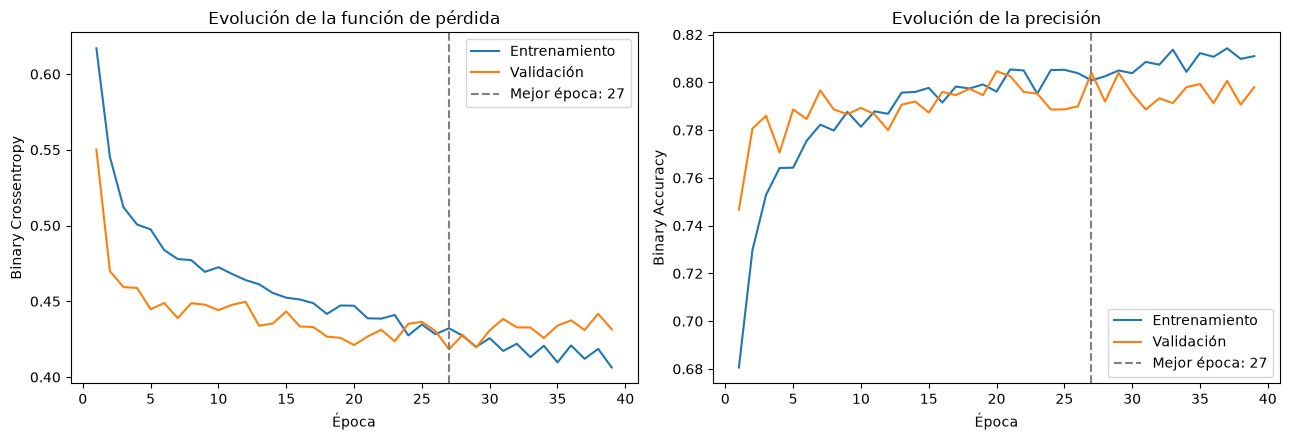

In [8]:
epochs_axis = np.arange(1, epochs_executed + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(epochs_axis, history_df["loss"], label="Entrenamiento")
axes[0].plot(epochs_axis, history_df["val_loss"], label="Validación")
axes[0].axvline(best_epoch, color="gray", linestyle="--", label=f"Mejor época: {best_epoch}")
axes[0].set_title("Evolución de la función de pérdida")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Binary Crossentropy")
axes[0].legend()

axes[1].plot(epochs_axis, history_df["accuracy"], label="Entrenamiento")
axes[1].plot(epochs_axis, history_df["val_accuracy"], label="Validación")
axes[1].axvline(best_epoch, color="gray", linestyle="--", label=f"Mejor época: {best_epoch}")
axes[1].set_title("Evolución de la precisión")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Binary Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

### Interpretación de las curvas

La pérdida disminuye durante las primeras épocas y alcanza su mejor valor de validación en la época 27 (`val_loss = 0,4184`). Después, la pérdida de entrenamiento continúa descendiendo mientras `val_loss` fluctúa sin una mejora sostenida. La diferencia entre ROC-AUC de entrenamiento (0,8972) y validación (0,8669) sugiere sobreajuste leve.

Early Stopping detuvo el ajuste en la época 39, después de 12 épocas sin mejorar, y restauró los pesos de la época 27. Las curvas confirman que el modelo aprende; la accuracy se interpreta con cautela por el desbalance y la ponderación de clases.

## 8. Evaluación inicial en validación

En esta sección se evalúa inicialmente el desempeño del MLP sobre los 1.500 clientes del conjunto de validación.

Se calculan ROC-AUC, Average Precision y Brier Score para analizar la capacidad de discriminación y la calidad de las probabilidades estimadas.

Adicionalmente, se obtiene una matriz de confusión y un reporte de clasificación utilizando un umbral de 0,5 exclusivamente con fines diagnósticos.

La curva de calibración inicial evidencia una tendencia a sobreestimar las probabilidades de abandono. Por ello, se aplica una corrección aproximada basada en los pesos de clase utilizados durante el entrenamiento.

Se comparan las probabilidades originales y ajustadas mediante sus métricas y curvas de calibración. La corrección reduce el Brier Score de 0,1354 a 0,1007, mientras que ROC-AUC y Average Precision permanecen sin cambios.

Esta corrección no modifica los pesos ni la arquitectura de la red neuronal. Su desempeño se comprueba posteriormente sobre el conjunto de prueba independiente.

In [9]:
validation_probabilities = model.predict(X_val_processed, verbose=0).reshape(-1)

probabilities_are_finite = bool(np.isfinite(validation_probabilities).all())
probabilities_in_range = bool(
    ((validation_probabilities >= 0) & (validation_probabilities <= 1)).all()
)
if not probabilities_are_finite or not probabilities_in_range:
    raise ValueError("Las probabilidades de validación no son finitas o están fuera de [0, 1].")

validation_roc_auc = float(roc_auc_score(y_val_array, validation_probabilities))
validation_average_precision = float(
    average_precision_score(y_val_array, validation_probabilities)
)
validation_brier_score = float(
    brier_score_loss(y_val_array, validation_probabilities)
)

prediction_checks = pd.DataFrame({
    "comprobación": [
        "Cantidad de probabilidades", "Probabilidades finitas",
        "Probabilidades dentro de [0, 1]", "Probabilidad mínima",
        "Probabilidad máxima",
    ],
    "resultado": [
        len(validation_probabilities), probabilities_are_finite,
        probabilities_in_range, validation_probabilities.min(),
        validation_probabilities.max(),
    ],
})
display(prediction_checks)

validation_metrics = pd.DataFrame({
    "métrica": ["ROC-AUC", "Average Precision", "Brier Score"],
    "validación": [
        validation_roc_auc,
        validation_average_precision,
        validation_brier_score,
    ],
})
display(validation_metrics.round(4))

,comprobación,resultado
0,Cantidad de probabilidades,1500
1,Probabilidades finitas,True
2,"Probabilidades dentro de [0, 1]",True
3,Probabilidad mínima,0.000411
4,Probabilidad máxima,1.0


,métrica,validación
0,ROC-AUC,0.8669
1,Average Precision,0.7099
2,Brier Score,0.1354


              precision    recall  f1-score   support

   Permanece     0.9261    0.8191    0.8693      1194
    Abandona     0.5135    0.7451    0.6080       306

    accuracy                         0.8040      1500
   macro avg     0.7198    0.7821    0.7387      1500
weighted avg     0.8420    0.8040    0.8160      1500



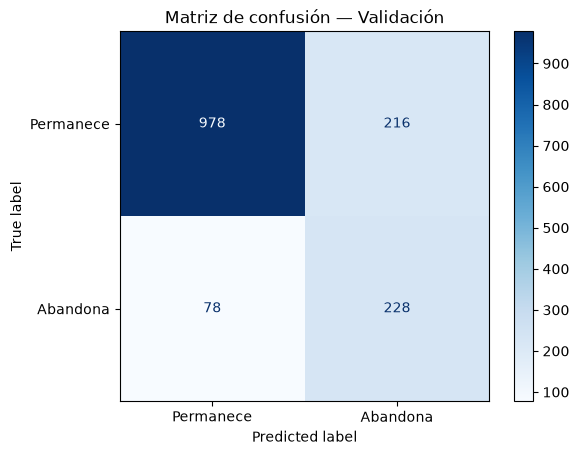

In [10]:
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
)

# Umbral únicamente para evaluación diagnóstica
umbral = 0.5

y_pred = (validation_probabilities >= umbral).astype(int)
y_real = y_val_array.astype(int)

print(classification_report(
    y_real,
    y_pred,
    target_names=["Permanece", "Abandona"],
    digits=4,
))

ConfusionMatrixDisplay.from_predictions(
    y_real,
    y_pred,
    display_labels=["Permanece", "Abandona"],
    cmap="Blues",
)

plt.title("Matriz de confusión — Validación")
plt.show()

De los 306 clientes que realmente abandonaron, la red identificó correctamente 228 y no detectó 78.

Por otro lado, de los 1.194 clientes que permanecieron, identificó correctamente 978, pero clasificó a 216 como posibles abandonos.

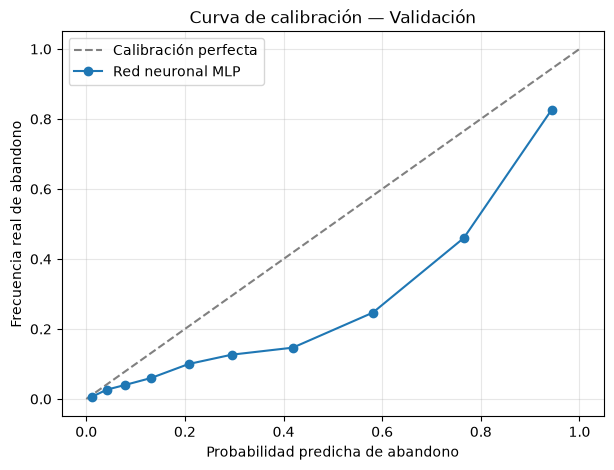

In [11]:
from sklearn.calibration import calibration_curve

prob_real, prob_predicha = calibration_curve(
    y_val_array,
    validation_probabilities,
    n_bins=10,
    strategy="quantile"
)

plt.figure(figsize=(7, 5))

plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="gray",
    label="Calibración perfecta"
)

plt.plot(
    prob_predicha,
    prob_real,
    marker="o",
    label="Red neuronal MLP"
)

plt.xlabel("Probabilidad predicha de abandono")
plt.ylabel("Frecuencia real de abandono")
plt.title("Curva de calibración — Validación")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [12]:
# Corrección aproximada por ponderación de clases

w0 = class_weights[0]
w1 = class_weights[1]

def corregir_probabilidades(probabilidades):
    p = np.asarray(probabilidades, dtype=np.float64)
    factor = w1 / w0

    return p / (p + factor * (1 - p))

validation_probabilities_adjusted = corregir_probabilidades(
    validation_probabilities
)

comparacion = pd.DataFrame({
    "Métrica": [
        "Brier Score",
        "ROC-AUC",
        "Average Precision"
    ],
    "Original": [
        brier_score_loss(y_val_array, validation_probabilities),
        roc_auc_score(y_val_array, validation_probabilities),
        average_precision_score(y_val_array, validation_probabilities)
    ],
    "Ajustada": [
        brier_score_loss(y_val_array, validation_probabilities_adjusted),
        roc_auc_score(y_val_array, validation_probabilities_adjusted),
        average_precision_score(y_val_array, validation_probabilities_adjusted)
    ]
})

display(comparacion.round(4))

,Métrica,Original,Ajustada
0,Brier Score,0.1354,0.1007
1,ROC-AUC,0.8669,0.8669
2,Average Precision,0.7099,0.7099


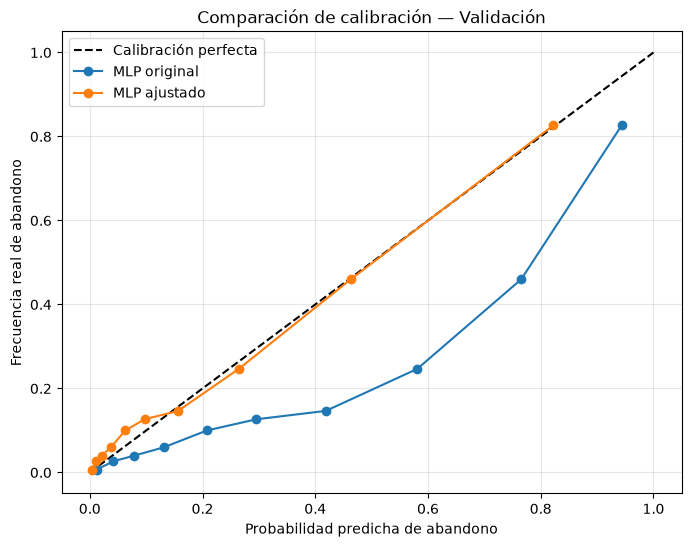

In [13]:
from sklearn.calibration import calibration_curve

plt.figure(figsize=(8, 6))

plt.plot(
    [0, 1], [0, 1],
    "k--",
    label="Calibración perfecta"
)

for probabilidades, nombre in [
    (validation_probabilities, "MLP original"),
    (validation_probabilities_adjusted, "MLP ajustado")
]:
    prob_real, prob_pred = calibration_curve(
        y_val_array,
        probabilidades,
        n_bins=10,
        strategy="quantile"
    )

    plt.plot(
        prob_pred,
        prob_real,
        marker="o",
        label=nombre
    )

plt.xlabel("Probabilidad predicha de abandono")
plt.ylabel("Frecuencia real de abandono")
plt.title("Comparación de calibración — Validación")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 9. Exportación del modelo y configuración de corrección

Después de seleccionar el modelo y la corrección de probabilidades mediante el conjunto de validación, se guardan los artefactos necesarios para su posterior utilización en la aplicación.

El MLP se exporta en formato Keras (`.keras`) y los parámetros de corrección se almacenan en un archivo JSON.

Se verifica que el modelo exportado pueda recargarse y que sus predicciones coincidan con las obtenidas antes de guardarlo.

In [14]:
# Guardar el modelo y la configuración de corrección

PROJECT_ROOT = PROCESSED_DIR.parent.parent
MODELS_DIR = PROJECT_ROOT / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = MODELS_DIR / "modelo_churn.keras"
CORRECTION_PATH = MODELS_DIR / "correccion_probabilidades.json"

# Guardar red neuronal con los mejores pesos restaurados
model.save(MODEL_PATH)

# Guardar los parámetros de la corrección
correction_config = {
    "method": "class_weight_prior_correction",
    "class_weight_0": float(class_weights[0]),
    "class_weight_1": float(class_weights[1]),
    "artifact_id": metadata["artifact_id"],
    "features": metadata["transformed_features"]
}

CORRECTION_PATH.write_text(
    json.dumps(correction_config, indent=4),
    encoding="utf-8"
)

# Verificar que la red puede recargarse
loaded_model = tf.keras.models.load_model(MODEL_PATH)

original_predictions = model.predict(
    X_val_processed, verbose=0
)

loaded_predictions = loaded_model.predict(
    X_val_processed, verbose=0
)

assert np.allclose(
    original_predictions,
    loaded_predictions,
    atol=1e-6
), "Las predicciones no coinciden después de recargar."

print("Modelo guardado:", MODEL_PATH)
print("Corrección guardada:", CORRECTION_PATH)
print("Verificación de recarga: correcta")

Modelo guardado: ..\models\modelo_churn.keras
Corrección guardada: ..\models\correccion_probabilidades.json
Verificación de recarga: correcta


## 10. Evaluación final en el conjunto de prueba

Se realiza una evaluación independiente utilizando los 1.500 clientes de `test.npz`, que no participaron en el entrenamiento ni en la selección de la corrección de probabilidades.

Se comparan las probabilidades originales y ajustadas mediante ROC-AUC, Average Precision y Brier Score.

También se obtiene una matriz de confusión y un reporte de clasificación utilizando un umbral diagnóstico de 0,5, así como las curvas de calibración correspondientes.

Los resultados de esta evaluación permiten comprobar el comportamiento del modelo sobre datos no utilizados anteriormente para ajustar sus parámetros.

In [15]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    classification_report,
    ConfusionMatrixDisplay
)

# Cargar datos de prueba
TEST_PATH = PROCESSED_DIR / "test.npz"

with np.load(TEST_PATH, allow_pickle=False) as test_data:
    X_test_processed = test_data["X"].copy()
    y_test_array = test_data["y"].copy()
    test_artifact_id = test_data["artifact_id"].item()

assert test_artifact_id == metadata["artifact_id"]
assert X_test_processed.shape == (1500, 11)
assert y_test_array.shape == (1500,)

# Cargar la configuración guardada
saved_config = json.loads(
    CORRECTION_PATH.read_text(encoding="utf-8")
)

assert saved_config["artifact_id"] == metadata["artifact_id"]

# Probabilidades originales del modelo exportado
test_probabilities = loaded_model.predict(
    X_test_processed, verbose=0
).reshape(-1)

# Corrección por pesos de clase
factor = (
    saved_config["class_weight_1"]
    / saved_config["class_weight_0"]
)

test_probabilities_adjusted = (
    test_probabilities
    / (test_probabilities + factor * (1 - test_probabilities))
)

# Verificación
assert np.isfinite(test_probabilities_adjusted).all()
assert ((test_probabilities_adjusted >= 0) &
        (test_probabilities_adjusted <= 1)).all()

# Comparación
test_metrics = pd.DataFrame({
    "Métrica": [
        "Brier Score",
        "ROC-AUC",
        "Average Precision"
    ],
    "Original": [
        brier_score_loss(y_test_array, test_probabilities),
        roc_auc_score(y_test_array, test_probabilities),
        average_precision_score(y_test_array, test_probabilities)
    ],
    "Ajustada": [
        brier_score_loss(y_test_array, test_probabilities_adjusted),
        roc_auc_score(y_test_array, test_probabilities_adjusted),
        average_precision_score(
            y_test_array,
            test_probabilities_adjusted
        )
    ]
})

display(test_metrics.round(4))

,Métrica,Original,Ajustada
0,Brier Score,0.1365,0.0995
1,ROC-AUC,0.8635,0.8635
2,Average Precision,0.7200,0.7200


REPORTE DE CLASIFICACIÓN — TEST
              precision    recall  f1-score   support

   Permanece     0.8844    0.9607    0.9210      1195
    Abandona     0.7673    0.5082    0.6114       305

    accuracy                         0.8687      1500
   macro avg     0.8259    0.7344    0.7662      1500
weighted avg     0.8606    0.8687    0.8580      1500



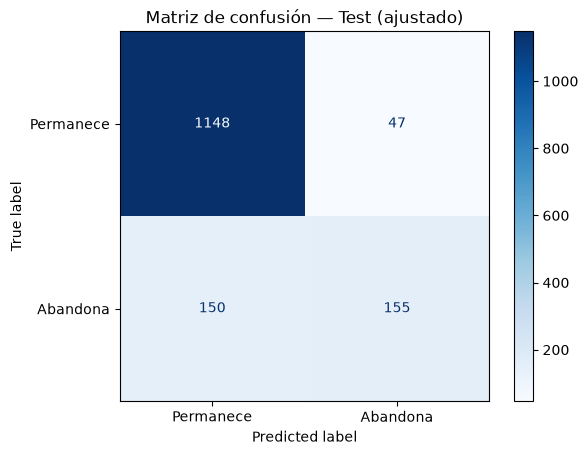

In [16]:
y_test_pred = (
    test_probabilities_adjusted >= 0.5
).astype(int)

print("REPORTE DE CLASIFICACIÓN — TEST")

print(classification_report(
    y_test_array.astype(int),
    y_test_pred,
    target_names=["Permanece", "Abandona"],
    digits=4
))

ConfusionMatrixDisplay.from_predictions(
    y_test_array.astype(int),
    y_test_pred,
    display_labels=["Permanece", "Abandona"],
    cmap="Blues"
)

plt.title("Matriz de confusión — Test (ajustado)")
plt.show()

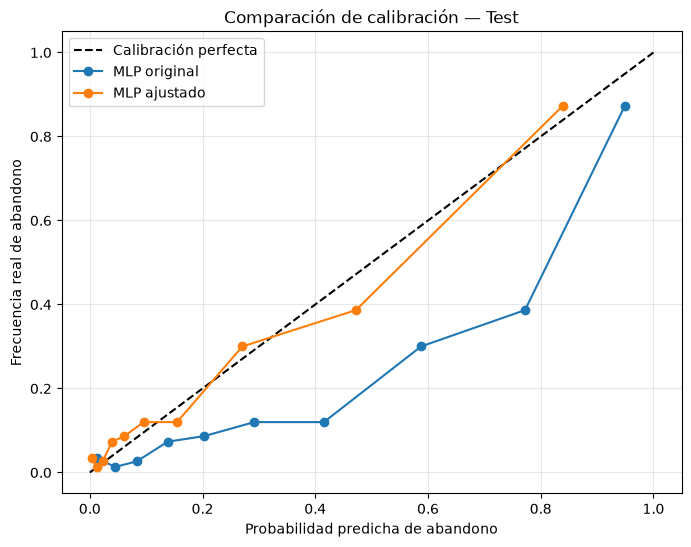

In [17]:
from sklearn.calibration import calibration_curve

plt.figure(figsize=(8, 6))

plt.plot(
    [0, 1], [0, 1],
    "k--",
    label="Calibración perfecta"
)

for probabilidades, nombre in [
    (test_probabilities, "MLP original"),
    (test_probabilities_adjusted, "MLP ajustado")
]:
    prob_real, prob_pred = calibration_curve(
        y_test_array,
        probabilidades,
        n_bins=10,
        strategy="quantile"
    )

    plt.plot(
        prob_pred,
        prob_real,
        marker="o",
        label=nombre
    )

plt.xlabel("Probabilidad predicha de abandono")
plt.ylabel("Frecuencia real de abandono")
plt.title("Comparación de calibración — Test")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 11. Resultados y conclusiones

### 11.1. Configuración del modelo

Se desarrolló un perceptrón multicapa (MLP) mediante TensorFlow/Keras, utilizando 11 características de entrada obtenidas del preprocesamiento.

La arquitectura está compuesta por una primera capa de 128 neuronas con activación ReLU, Batch Normalization y Dropout de 0,25; una segunda capa de 64 neuronas con ReLU y Dropout de 0,15; y una neurona de salida con activación Sigmoid.

El modelo contiene 10.369 parámetros, de los cuales 10.113 son entrenables.

El entrenamiento utilizó Adam, Binary Crossentropy, lotes de 32 registros, ponderación de clases y Early Stopping con paciencia de 12 épocas.

Se ejecutaron 39 épocas y se restauraron los pesos correspondientes a la época 27, que obtuvo la menor pérdida de validación (0,4184).

### 11.2. Resultados de validación

El modelo original obtuvo los siguientes resultados:

| Métrica | Resultado |
|---|---:|
| Accuracy | 0,8040 |
| ROC-AUC | 0,8669 |
| Average Precision | 0,7099 |
| Brier Score | 0,1354 |

La matriz de confusión mostró 978 verdaderos negativos, 216 falsos positivos, 78 falsos negativos y 228 verdaderos positivos.

El Recall de la clase Abandona fue de 74,51 %, mientras que su Precision fue de 51,35 %.

La curva de calibración reveló una sobreestimación sistemática de las probabilidades de abandono.

Para mejorar estas estimaciones, se aplicó una corrección aproximada basada en los pesos de clase, reduciendo el Brier Score de 0,1354 a 0,1007.

La capacidad de discriminación se mantuvo, con ROC-AUC de 0,8669 y Average Precision de 0,7099.

### 11.3. Evaluación final en prueba

La evaluación final se realizó utilizando los 1.500 registros del conjunto de prueba.

Los resultados obtenidos fueron:

| Métrica | Original | Ajustado |
|---|---:|---:|
| Brier Score | 0,1365 | 0,0995 |
| ROC-AUC | 0,8635 | 0,8635 |
| Average Precision | 0,7200 | 0,7200 |

La corrección redujo aproximadamente un 27,1 % el Brier Score respecto al modelo original en el conjunto de prueba.

Las curvas de calibración confirmaron una mejor correspondencia entre las probabilidades ajustadas y las frecuencias observadas de abandono.

Utilizando un umbral diagnóstico de 0,5 sobre las probabilidades ajustadas, se obtuvo una Accuracy de 86,87 %.

La matriz de confusión presentó 1.148 verdaderos negativos, 47 falsos positivos, 150 falsos negativos y 155 verdaderos positivos.

Para la clase Abandona se obtuvo una Precision de 76,73 %, un Recall de 50,82 % y un F1-Score de 61,14 %.

Este resultado evidencia que, bajo el umbral de 0,5, las probabilidades ajustadas generan menos falsas alarmas, aunque también disminuye la detección de abandonos.

La decisión comercial del sistema no dependerá de dicho umbral, sino del cálculo de ganancia neta esperada.

### 11.4. Exportación del modelo

Se exportaron los siguientes artefactos:

- `models/modelo_churn.keras`: red neuronal entrenada con los mejores pesos restaurados.
- `models/correccion_probabilidades.json`: configuración de la corrección basada en los pesos de clase.
- `models/preprocesador.joblib`: transformador generado previamente durante el preprocesamiento.

La recarga del modelo fue verificada y sus predicciones coincidieron con las obtenidas antes de la exportación.

Estos artefactos permitirán implementar posteriormente la inferencia sin necesidad de volver a entrenar la red neuronal.

### 11.5. Conclusiones

El MLP desarrollado presenta una capacidad de discriminación favorable para el problema académico de predicción de abandono, con un ROC-AUC de 0,8635 en el conjunto de prueba.

La separación de los datos, el escalado, la codificación categórica, la ponderación de clases y Early Stopping permitieron desarrollar un procedimiento reproducible y limitar el sobreajuste.

La corrección de probabilidades mejoró considerablemente el Brier Score, manteniendo la capacidad de discriminación del modelo original. Sin embargo, la calibración no es perfecta y sus resultados dependen de las características del dataset.

La evaluación independiente mostró resultados consistentes con los obtenidos en validación, lo que respalda la utilización de esta versión como primer modelo predictivo del proyecto.

Las probabilidades ajustadas podrán utilizarse como entrada del futuro motor financiero, encargado de evaluar la rentabilidad de las intervenciones mediante la ganancia neta esperada (GNE).

Los resultados corresponden a un ejercicio académico sobre datos históricos y no constituyen una validación para su utilización directa en una entidad bancaria real.